# 딥러닝 ② 요약본

## 1. 인트로

### 1-1. RNN의 한계와 어텐션의 등장

**1) Seq2Seq 복습**
- 입력 시퀀스를 받아 다른 시퀀스로 변환하는 모델 구조
- 장점
   - 입력과 출력의 길이(단어 개수)가 달라도 사용 가능 (예: 영어 3개 단어 → 한국어 5개 단어)
   - 번역, 요약, 음성 인식 등 다양한 변환 작업에 사용 가능


| 구성 요소 | 역할 |
|---|---|
| Encoder | 입력 문장("I, study, math, hard")을 LSTM이 순차적으로 한 단어씩 읽은 후, 문장 전체 의미를 요약하여 하나의 벡터(Context Vector)로 압축 |
| Context Vector | 인코더가 만든 문장 요약본이자 인코더와 디코더를 잇는 유일한 통로 |
| Decoder | Context Vector를 받아 번역문을 한 단어씩 생성 (`<sos>` → "나는" → "수학을" → … → `<eos>`) |

**2) Attention의 등장배경: Seq2Seq의 병목 현상**
- Context Vector의 크기가 고정되어 있어, 입력이 5단어든 50단어든 같은 크기의 벡터에 모든 정보를 담아야 함 -> 문장이 길어질수록 정보 손실 발생
- 디코더는 출력 단어마다 똑같은 요약본을 참고하므로, 단어마다 필요한 정보를 다르게 반영할 수 없음
- Context Vector는 인코더의 마지막 hidden state이므로, 앞쪽 단어 정보는 여러 단계를 거치며 희미해짐

**3) Attention의 정의**
- 현재 시점에서 가장 중요한 부분에 더 높은 가중치를 부여하는 기술
- 출력 단어를 생성할 때 입력 문장 속 단어들 중 어떤 단어에 더 집중할지의 정도를 결정

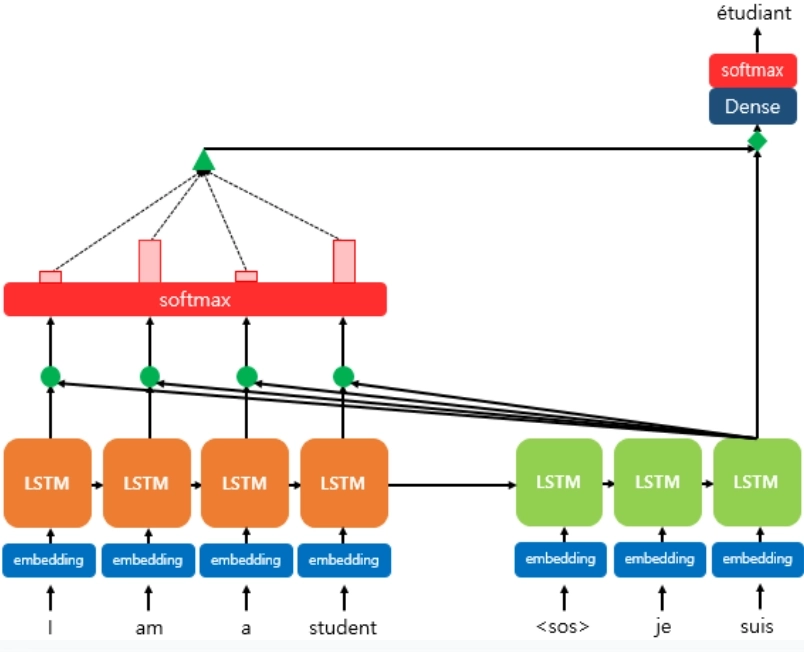

> 기존 Seq2Seq는 원문 정보를 순차적으로 전달받은 결과만 사용하는 반면, Attention은 디코더와 인코더의 모든 위치를 직접 비교
> <br> 각 단어와의 관련도 점수는 서로를 기다릴 필요 없이 동시에 계산 가능

**4) Attention의 과정**

- ① 입력을 벡터 형태로 변환: 입력 단어를 컴퓨터가 읽을 수 있는 숫자 벡터로 변환
- ② 단어별 중요도 계산
   - 관련도 점수: 현재 작업과 각 단어 사이의 관계가 얼마나 높고 유사한지 점수화
   - Softmax: 관련도 점수를 0~1 사이의 확률 값으로 변환, 이 비율을 Attention Weight라고 함
   - 예: student가 3.8점의 관련도 점수를 받아 Softmax 후 80%의 가중치 -> "student 단어에 80%를 집중"
- ③ 중요도에 따른 입력 정보 조합: 어텐션 가중치만큼 각 단어의 hidden state를 섞어 Context Vector 생성 -> 비율이 가장 높은 단어 정보를 위주로 반영

**5) 정리**
| 모델 | 한계 |
|---|---|
| RNN | 장기 의존성 문제 + 병렬화 불가 |
| LSTM | 장기 의존성은 완화했지만 순차 구조는 그대로 |
| Seq2Seq + Attention | 병목 현상은 해결했지만 여전히 RNN 위에서 작동하는 보조 역할 |

> 인코더와 디코더가 여전히 LSTM으로 한 칸씩 순서대로 처리되기 때문에 모델 전체의 병렬화는 이루어지지 않음
> <br> LSTM을 걷어내고 어텐션만 남긴 모델 = Transformer

### 1-2. Attention is All You Need

**1) Transformer 구조를 처음 발표한 논문 (Self-Attention 방식)**
- 2017년 NIPS에서 Google Brain·Google Research 연구진 8명이 발표
- 제목 그대로 "Attention만 있으면 된다"는 주장을 담은 논문으로 오늘날 LLM의 기반이 됨

**2) 논문 내용**
- 논문 배경: RNN과 RNN 기반 모델들의 한계
   - RNN, LSTM, GRU는 당시 번역 등 시퀀스 작업의 표준 모델
   - n번째 단어를 계산하려면 n-1번째 결과가 먼저 나와야 하는 순차적 구조 -> 한 문장 안에서 병렬 처리 불가
   - Attention은 거리와 상관없이 단어 관계를 잘 잡는 도구였지만 RNN의 보조적 역할에 그침
- Transformer의 등장: RNN과 CNN을 완전히 제거하고 Self-Attention으로 입력과 출력의 관계를 계산하는 모델 제안
- 가장 중요한 발견: "Recurrence(순환)와 Convolution(합성곱)은 필수가 아니다"
   - Attention만으로 더 좋은 성능을 낼 수 있고 순차 구조를 없앤 덕분에 병렬화를 통한 빠른 학습 속도가 가능
- 파급효과
   - LLM의 탄생: Transformer의 디코더를 쌓은 GPT, 인코더를 쌓은 BERT가 등장하며 대형 언어 모델의 기반이 됨
   - NLP 평정: 번역, 요약, 질의응답 등 자연어 처리 대부분의 표준 구조로 자리잡음
   - 타 분야로의 확장: 이미지, 음성 등으로 확장

**3) Transformer란?**

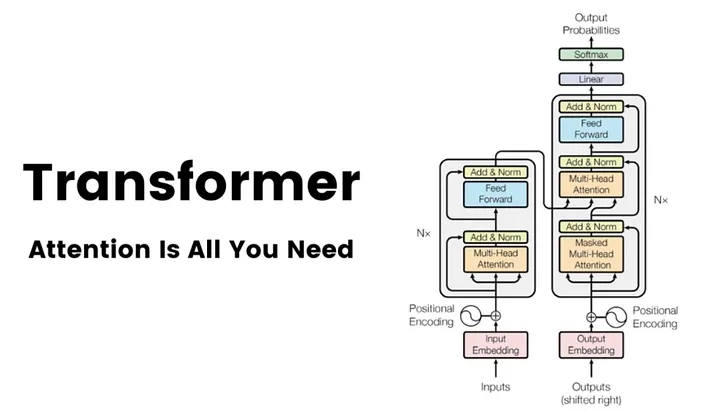

- 정의: RNN처럼 단어를 순서대로 처리하지 않고, Attention만으로 문장 전체의 의미와 구조를 파악하여 한 번에 처리하는 인코더-디코더 모델
- 구조
   - 왼쪽(인코더): 입력 문장 이해
   - 오른쪽(디코더): 출력 문장 생성
   - 회색 상자(층) 하나를 N개 쌓아 인코더와 디코더를 구성

| 구분 | Seq2Seq + Attention | Transformer |
|---|---|---|
| 인코더, 디코더의 내부 | LSTM (순차 처리) | Self-Attention |
| 어텐션의 역할 | RNN을 돕는 보조 역할 | 모델 그 자체 |
| 어텐션 사용 위치 | 디코더 -> 인코더 1곳 | 인코더 내부, 디코더 내부, 인코더-디코더 사이 3곳 |
| 단어 순서 정보 | RNN이 순서대로 읽으며 반영 | Positional Encoding으로 따로 추가 |
| 병렬 처리 | 불가 | 가능 |

**4) Transformer의 핵심 기술**
- Self-Attention: 문장 안의 단어들이 서로를 참고해 얼마나 중요한 관계를 맺고 있는지 한 번에 문맥을 파악하는 기술
- Multi-Head Attention: Attention을 여러 갈래로 나눠 다양한 관점에서 관계를 파악
- Positional Encoding: 각 단어의 위치를 벡터로 만들어 단어 벡터에 더함으로써 사라진 순서 정보를 보완



## 2. Self-Attention

### 2-1. Query, Key, Value

**1) RNN의 한계**
- LSTM은 기억을 전달하는 방식을 개선했지만 순서대로 처리하는 구조 자체는 바꾸지 못함
- Transformer는 구조 자체를 바꾸어 순서대로 전달하는 대신 모든 단어를 서로 직접 비교
- 이때 단어끼리 비교하는 데 쓰이는 것이 Query, Key, Value

**2) Q, K, V 개념**
> Attention은 Query를 Key들과 비교해 관련도를 구하고 그 비율만큼 Value를 섞어 결과를 생성하는 계산

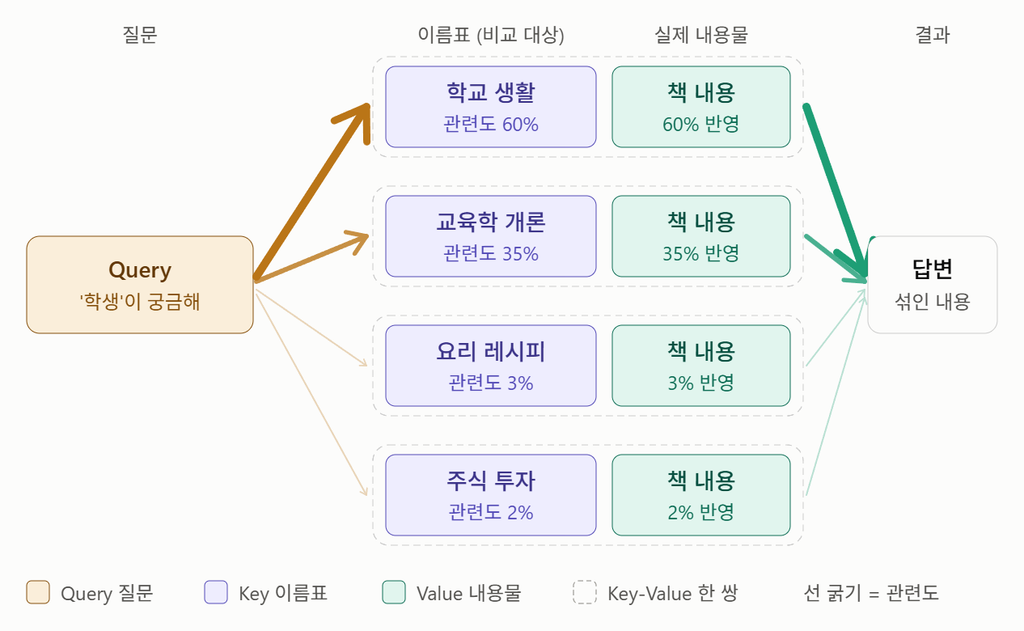

| 구분 | 정의 | 역할 |
|---|---|---|
| Q: Query(쿼리) | 현재 처리 중인 단어가 다른 단어들에게 "지금 나한테 필요한 정보가 뭐지?"라고 묻는 벡터 | 질문 |
| K: Key(키) | 각 단어가 "나는 이런 정보를 가지고 있어"라고 보이는 벡터 | Query와 비교하여 관련도 점수 결정 |
| V: Value(밸류) | 각 단어가 실제로 전달하는 정보 벡터 | 관련도 비율만큼 모든 Value를 섞어 최종 결과 생성 |

### 2-2. 기존 Cross-Attention vs. Self-Attention

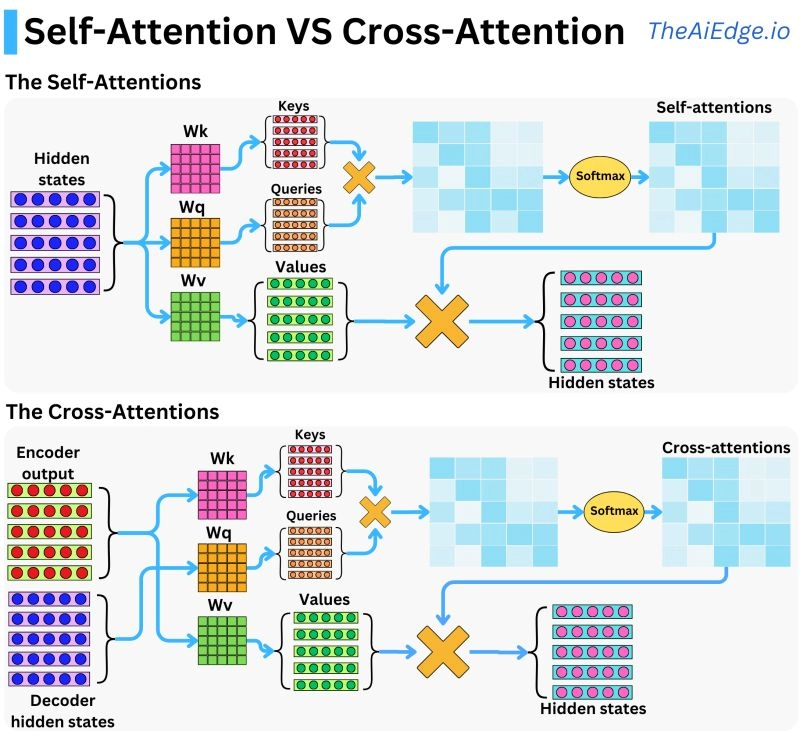


> Seq2Seq의 Attention은 디코더가 인코더를 참고하는 Cross-Attention
> <br> Transformer는 한 걸음 더 나아가 문장이 자기 자신을 참고하는 Self-Attention이 핵심임

**1) 기존 Attention in Seq2Seq (Cross-Attention)**
- Query와 Key-Value쌍이 서로 다른 시퀀스에서 출력
- 하나의 시퀀스가 독립된 다른 시퀀스를 참고하여 정보를 만들어내는 매커니즘

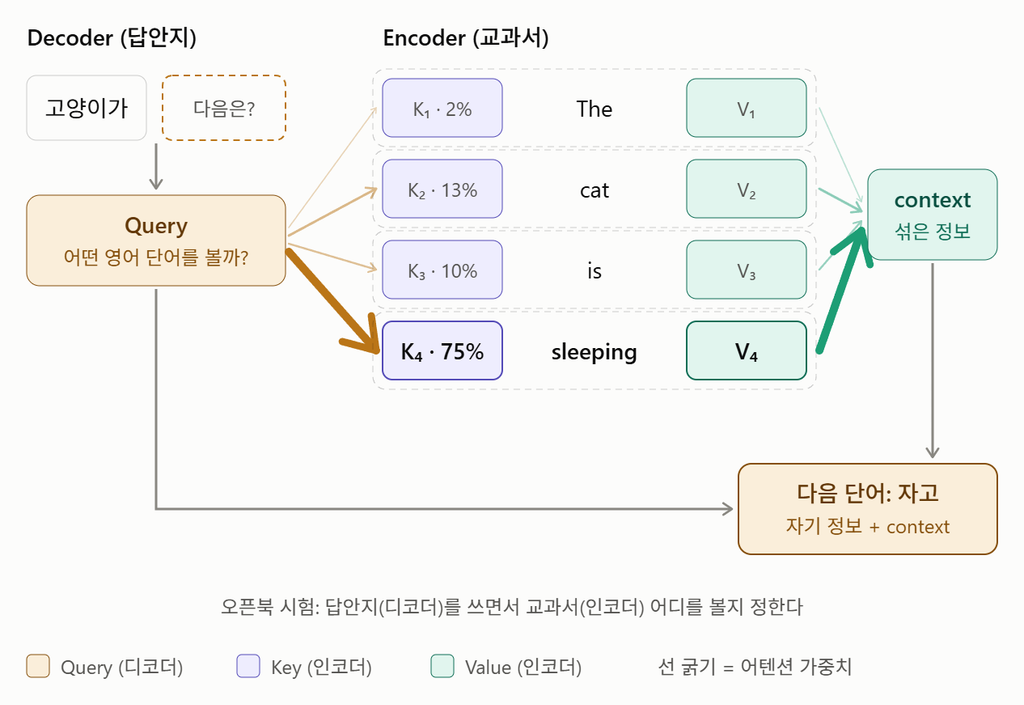

- 핵심 과정 (예: 원문 "The cat is sleeping" → 번역 중 "고양이가 ___", 다음 단어를 만드는 순간)
   - ① Query 만들기: 디코더가 지금까지 만든 "고양이가"를 바탕으로 현재 상태를 Query로 만듦 → "다음 단어를 위해 어떤 영어 단어를 봐야 할까?"
   - ② Key, Value 불러오기: 인코더가 원문의 각 단어(The, cat, is, sleeping)에 대해 만들어 둔 벡터를 Key와 Value로 사용
   - ③ 유사도 계산 (Attention Score): Query와 각 Key의 관련도를 $Q \cdot K_i$(내적)로 계산하고 Softmax로 확률 값 비율로 변환 → The 2%, cat 13%, is 10%, sleeping 75%
   - ④ Weighted Sum: 비율만큼 Value를 섞어 Context Vector 생성 → 디코더 자기 정보 + Context Vector로 다음 단어 "자고" 출력

> 디코더를 쓰면서 인코더의 어디를 볼지 계속 정하는 과정
> <br> 인코더와 디코더가 RNN 위에서 작동하기 때문에 원문 내부의 관계는 RNN이 순서대로 읽으며 간접적으로 파악하고 병렬 처리가 불가하다는 한계가 있음

**2) Self-Attention**
- Query와 Key-Value쌍이 같은 시퀀스에서 출력
- RNN 없이도 문장 내부의 관계와 문맥을 직접 파악

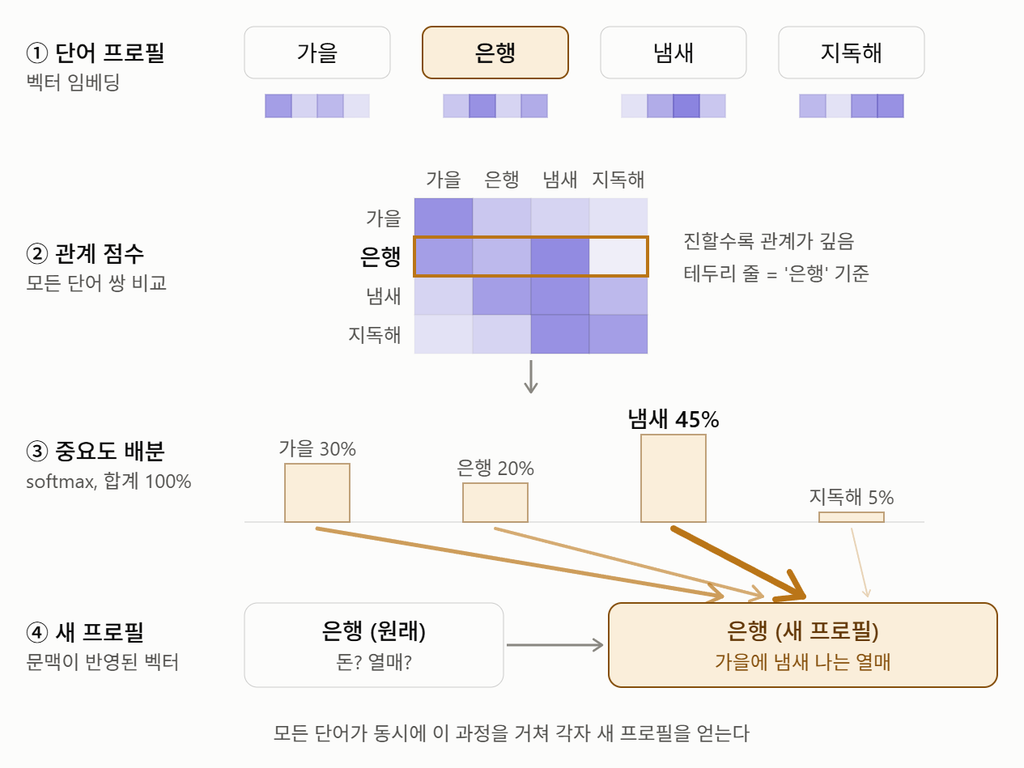

- 핵심 과정 (예: "가을 은행 냄새 지독해"에서 '은행'의 의미 파악)
   - ① 벡터 임베딩: 각 단어를 벡터로 변환하고, 같은 벡터에서 Q, K, V를 만듦
   - ② 내적 및 관련도 점수: '은행'의 Query와 모든 단어의 Key를 비교해 관계 점수 계산 (가로줄 = 질문하는 단어, 세로줄 = 참고 대상)
   - ③ 중요도 배분 (Softmax & 어텐션 가중치): 가을 30%, 은행 20%, 냄새 45%, 지독해 5%로 비율 변환
   - ④ 새로운 벡터 생성: 비율만큼 Value를 섞어 '은행'이 "돈? 열매?"에서 "가을에 냄새 나는 열매"라는 의미를 담은 새 벡터가 됨

> 이 과정을 모든 단어가 동시에 거쳐 각자 문맥이 반영된 새 벡터를 얻음 = 병렬 처리 가능

**3) 비교**
| 구분 | Cross-Attention | Self-Attention |
|---|---|---|
| point | 번역 중인 문장이 원문을 참고 | 문장 스스로 내부 관계를 파악 |
| 작동 방식 | 디코더의 Query로 인코더의 Key, Value를 조회 | 같은 문장에서 만든 Q, K, V로 모든 단어끼리 비교 |
| 참조 대상 | 서로 다른 시퀀스 (디코더 → 인코더) | 서로 같은 시퀀스 (문장 내부) |
| 주요 목적 | 고정 Context Vector의 병목 해결 | 문맥이 반영된 단어 표현 생성 |
| 결과 벡터 | Context Vector | 문맥이 반영된 새 표현 |
| 기반 아키텍처 | RNN | Transformer |
| 병렬처리 | RNN 기반일 때 불가능 | 가능 |

- Transformer는 두 방식을 모두 사용
   - 인코더: Self-Attention → 원문 단어끼리 관계 파악
   - 디코더: Self-Attention → 번역 중인 문장끼리 관계 파악 (단, 아직 만들지 않은 뒤쪽 단어는 보지 못하도록 가림)
   - 인코더-디코더 사이: Cross-Attention → 번역하면서 원문 참고

> Seq2Seq에서 RNN이 하던 문장 내부 이해는 Self-Attention이 대신하고 Attention이 하던 원문 참고는 Cross-Attention이 그대로 맡음
> <br> Cross는 "남에게 묻기", Self는 "나에게 묻기"


### 2-3. Scaled Dot-Product Attention
**1) Dot-Product Attention**
- Attention Score를 계산하는 가장 기본적인 방법 중 하나로, Query와 Key 벡터를 내적하여 관련도 점수를 구하는 방식
- 내적: 두 벡터의 같은 위치 성분끼리 곱해 모두 더한 값, 방향이 비슷할수록 큰 값

$$
Q \cdot K = \sum_{i=1}^{d_k} Q_i K_i
$$

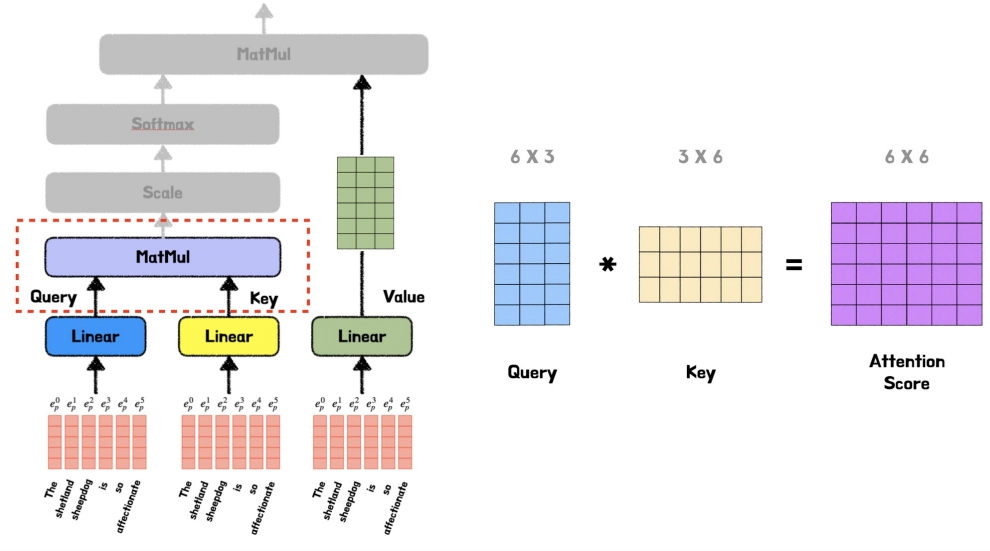

- 기본적인 과정
   - ① Attention Score 계산
      - Query(6×3)와 전치한 Key(3×6)를 곱함 → 결과(6×6): 모든 단어 × 모든 단어의 관련도 점수표
      - 행렬 곱셈 한 번으로 36개 점수를 동시에 계산 → 병렬 처리가 실제로 구현되는 지점
   - ② 계산된 값에 Softmax 적용 → Attention Weight 산출
      - 점수표의 각 가로줄을 합이 1인 비율로 전환 → "이 단어는 다른 단어들을 몇 %씩 참고하는가"를 나타냄
   - ③ 최종 결과값 계산
      - Attention Weight(6×6) × Value → 각 단어가 다른 단어 정보를 비율만큼 섞은 새 벡터 6개 (행 기준)

- 문제점: Attention Score의 극단화
   - 벡터 차원이 커질수록 내적 값이 지나치게 커질 수 있음
   - 극단적인 값이 Softmax에 입력되면 특정 단어에 확률이 과도하게 몰림. 기울기가 0에 가까워져 학습이 원활하게 진행되지 않는 Vanishing Gradient 문제 발생

**2) Scaled Dot-Product Attention**
- "Attention Is All You Need"의 저자들이 제안한 방식으로 Transformer의 Attention 계산 공식
- 기존 Dot-Product Attention의 문제를 해결하기 위해 내적과 Softmax 사이에 스케일링 단계 하나를 추가

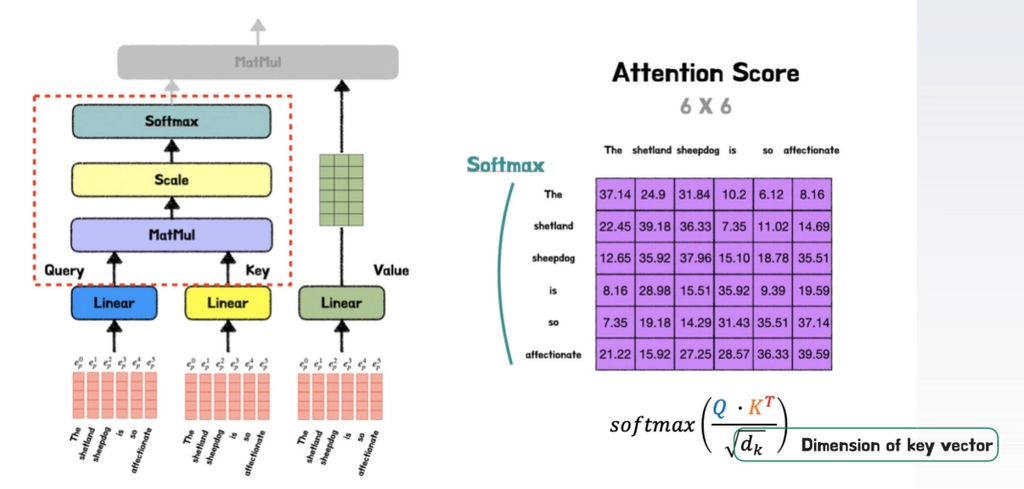

- 과정
   - ① Query와 모든 Key를 내적 → Attention Score
   - ② Attention Score를 $\sqrt{d_k}$로 나누는 스케일링 과정 진행
   - ③ Softmax 적용 → Attention Weight 산출
   - ④ Attention Weight × Value → 최종 결과
- $\sqrt{d_k}$로 나누면 분산이 다시 1 근처로 돌아와 차원의 크기와 상관없이 점수가 안정적인 범위에 머물 수 있음

$$
\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V
$$

- 계산의 결과로 얻어지는 벡터
   - Cross-Attention: Context Vector (현재 생성 중인 단어에 필요한 원문 정보를 비율만큼 모은 벡터)
   - Self-Attention: 문장 내 다른 단어들과의 관계가 반영되어 의미가 업데이트된 단어 벡터

## 3. Multi-Head Attention

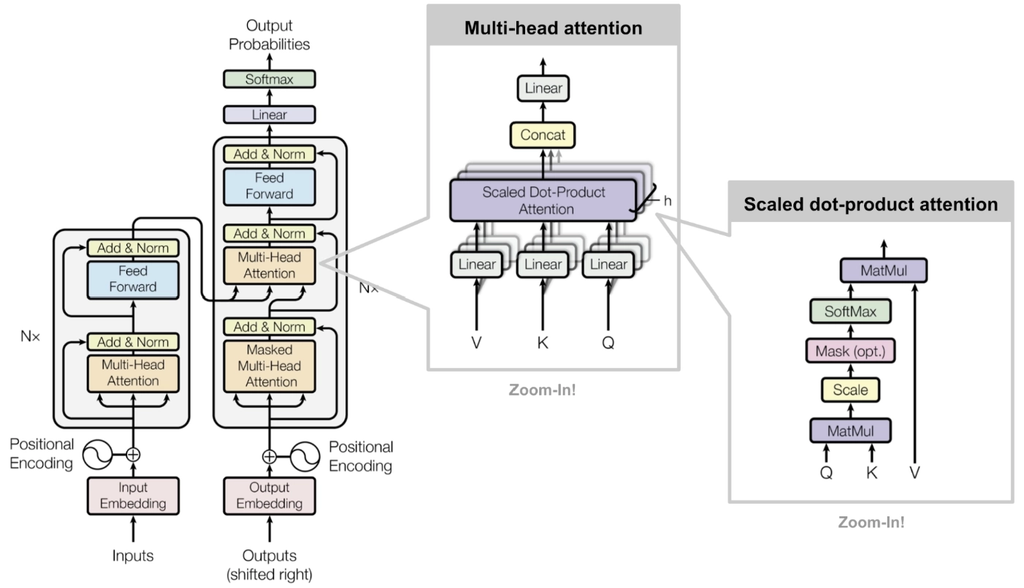

### 3-1. 왜 Multi-Head Attention을 사용할까?

**1) 헤드(Head)란?**
- Attention 계산을 한 번 하는 독립된 단위
   - 자기만의 가중치 행렬 세트 $W^Q, W^K, W^V$를 가지고
   - 그 행렬로 Q·K·V를 만들어 Attention을 한 번 계산하고
   - 결과 벡터 하나를 내놓음
- 헤드마다 가중치 행렬의 숫자가 다르기 때문에 같은 문장을 봐도 집중하는 단어가 달라짐

**2) Single-Head Attention VS. Multi-Head Attention**

| 구분 | Single-Head Attention | Multi-Head Attention |
|---|---|---|
| 정의 | 헤드가 1개 | Attention을 작게 쪼개서 여러 번 동시에 하는 방식 |
| 방식 | 가중치 행렬 세트 하나로 512차원 벡터를 그대로 한 번 Attention → 단어마다 가중치 분포가 하나 나옴 | 헤드마다 다른 가중치로 여러 관점의 가중치 분포를 각각 계산 |
| 한계 / 장점 | 집중력 100%를 혼자 나눠 써야 함 | 헤드마다 각자 100%를 씀 |

- Single-Head의 한계
   - Softmax를 거친 가중치는 합이 항상 1(100%)인데 한 단어를 이해하려면 여러 종류의 관계가 동시에 필요한 경우가 많음
   - 헤드가 하나뿐이면 100%를 여러 관계에 골고루 나눠 줄 수밖에 없고 결과는 여러 정보가 섞여 흐릿해진 벡터 하나가 됨

- Multi-Head Attention의 방식
   - ① 512차원 벡터에 헤드마다 다른 $W^Q, W^K, W^V$를 곱해서 64차원 Q, K, V를 8세트 만듦
   - ② 8개 헤드가 서로 간섭하지 않고 각자 Attention을 계산 (가중치 분포가 8개 나옴)
   - ③ 8개의 64차원 결과를 이어 붙여(Concat) 다시 512차원으로 만듦
   - ④ 마지막으로 $W^O$를 곱해서 8개의 관점을 하나로 섞음
   - 예: "Tom gave Mary a book yesterday"

| 헤드 | 주로 보는 단어 | 가중치 | 담당하는 질문 |
|---|---|---|---|
| 헤드 1 | Tom | 0.90 | Who? |
| 헤드 2 | Mary | 0.90 | To whom? |
| 헤드 3 | book | 0.90 | What? |
| 헤드 4 | yesterday | 0.90 | When? |

### 3-2. Multi-Head Attention 작동 방식
- "I love you"에서 love 한 단어가 Multi-Head Attention을 통과하는 과정
- 각 단어의 차원, 어텐션 헤드의 수, 각 헤드의 차원은 논문과 같이 각각 512차원, 8개, 64차원으로 가정

**1) 전체 흐름**
| 단계 | 하는 일 | 크기 변화 |
|---|---|---|
| ① 분할 (Projection) | 헤드마다 다른 W를 곱해 작은 Q·K·V를 만듦 | 512 → 64 × 8세트 |
| ② 병렬 어텐션 계산 (Attention) | 8개 헤드가 동시에, 서로 간섭 없이 Attention 계산 | 64 × 8개 결과 |
| ③ 결합 (Concat) | 8개 결과를 한 줄로 연결 | 64 × 8 → 512 |
| ④ 최종 투영 (Final Projection) | $W^O$를 곱해 8개 관점을 하나로 융합 | 512 → 512 |

**2) 단계별 설명**
- ① 분할 (Projection)
   - love를 나타내는 512차원 벡터 하나에 헤드마다 다른 가중치 행렬을 곱해서 64차원짜리 Q·K·V를 8세트 만듦

| 헤드 | Query | Key | Value |
|---|---|---|---|
| 헤드 1 | love × $W_1^Q$ → 64차원 | love × $W_1^K$ → 64차원 | love × $W_1^V$ → 64차원 |
| 헤드 2 | love × $W_2^Q$ → 64차원 | love × $W_2^K$ → 64차원 | love × $W_2^V$ → 64차원 |
| … | … | … | … |
| 헤드 8 | love × $W_8^Q$ → 64차원 | love × $W_8^K$ → 64차원 | love × $W_8^V$ → 64차원 |

   - 문장의 다른 단어(I, you)도 똑같이 8세트씩 만들어짐

- ② 병렬 어텐션 계산 (Attention)
   - 8개 헤드가 서로 간섭하지 않고 동시에 Scaled Dot-Product Attention 계산
   - 헤드 1:
      - 점수 매기기 (Score): love의 $Q_1$을 I, love, you의 $K_1$과 각각 내적하여 관련도 점수 3개 계산
      - 크기 조절 (Scale): 계산된 점수를 각 헤드 차원의 제곱근($\sqrt{64} = 8$)으로 나눔 (점수가 너무 커져 한 단어가 독차지하는 것을 막음)
      - 가중치 변환 (Softmax): 합이 1인 어텐션 가중치 생성 (예: I 0.2, love 0.7, you 0.1)
      - 섞기 (Weighted Sum): 이 가중치대로 I, love, you의 $V_1$에 곱해서 모두 더하면 헤드 1의 결과(64차원)
   - 헤드 2~8도 각자의 Q·K·V로 같은 계산을 동시에, 독립적으로 수행 -> 64차원 결과 8개

- ③ 이어 붙이기 (Concat)
   - 8개의 64차원 결과를 순서대로 한 줄로 이어 붙여 512차원(8×64) 벡터를 하나 만듦

- ④ 섞기 (Final Projection)
   - 이어 붙인 벡터는 아직 각 헤드의 분석 결과를 단순히 나열한 것
   - 벡터에 행렬 $W^O$(512×512)를 곱해 8개 관점을 하나의 의미로 융합

> 모든 단계가 끝나면 'love'라는 단어에 대한 Multi-Head Attention 레이어의 최종 출력 벡터를 얻게 됨


## 4. Transformer 전체 아키텍처

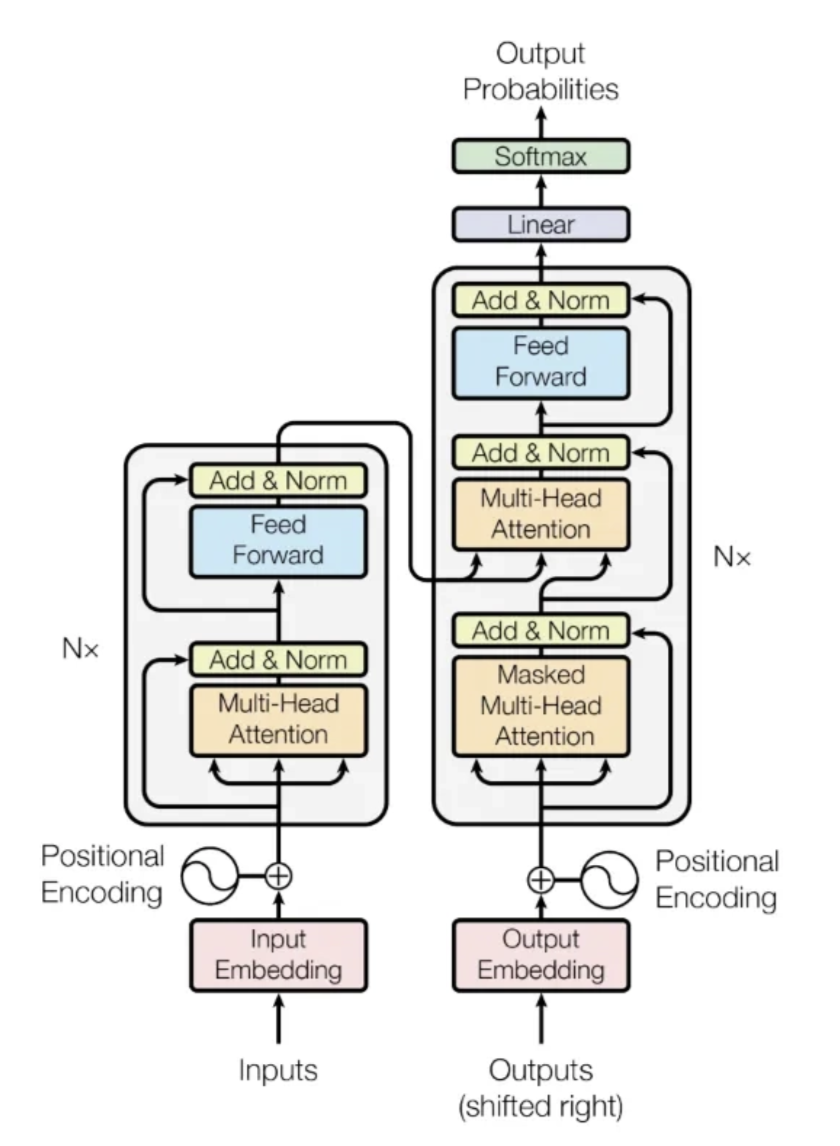

### 4-1. 트랜스포머의 전처리 단계
- Transformer는 텍스트 입력(Inputs) → 텍스트 토큰화(Tokenization) → 토큰 임베딩(Embedding) → Positional Encoding 순으로 동작

**1) 토큰화 (Tokenization)**
- 문장을 모델이 다루는 기본 단위(토큰)로 자르는 것

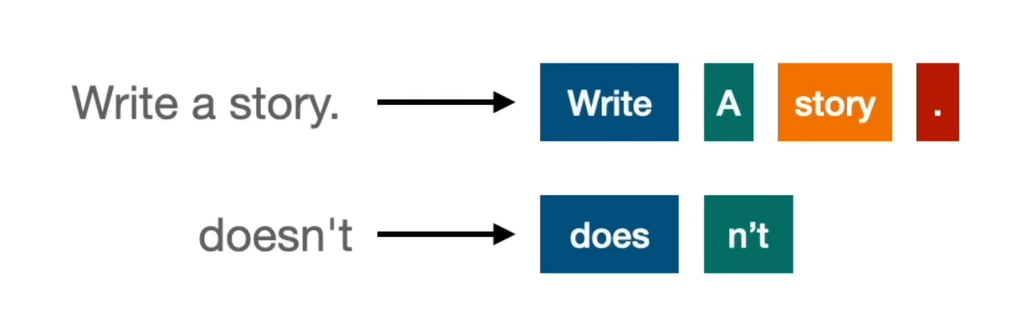

- 보통 단어 하나 = 토큰 하나
- 문장 부호도 토큰
- 길거나 드문 단어는 여러 조각으로 나눔
- 논문에서는 영→독 번역에 BPE 방식으로 약 37,000개, 영→불 번역에 word-piece 방식으로 32,000개의 토큰 사전을 사용

**2) 임베딩 (Embedding)**
- 각 토큰을 숫자(벡터)로 바꾸는 것으로, 이때 벡터의 길이가 벡터의 차원이 됨
- 임베딩의 원리: 단어 → 공간적 의미로 표현
   - 뜻이 비슷한 단어는 가까운 좌표에 놓임
   - 임베딩 값은 처음엔 무작위이고 학습하면서 점점 의미에 맞는 자리를 찾아감
   - 단어마다 기본적인 의미가 담긴 덕분에 이후 Attention이 단어 사이의 관계를 계산할 수 있음

**3) Positional Encoding**
- 단어들의 순서 정보를 임베딩 벡터에 추가하는 단계
- 왜 필요할까?
   - Transformer는 모든 단어를 한꺼번에 보기 때문에 그대로 두면 단어 순서를 모름
   - "개는 고양이를 쫓는다"와 "고양이는 개를 쫓는다"를 다르다고 구분하지 못하고 같은 단어 묶음으로 봄
   - RNN은 순서대로 읽어서 자연스럽게 알았지만 Transformer는 순서를 따로 알려줘야 함
- 어떻게?
   - 각 위치마다 정해진 512차원 '위치 벡터'를 만들어 임베딩에 더함 (이어 붙이는 게 아니라 숫자끼리 더함)
   - 1번째 자리에는 항상 벡터 A, 2번째 자리에는 항상 벡터 B…처럼 문장이 달라도 규칙은 같아야 모델이 순서를 배울 수 있음
   - 같은 단어라도 자리가 다르면 최종 벡터가 달라짐

### 4-2. 트랜스포머의 Encoder와 Decoder

**1) Encoder**

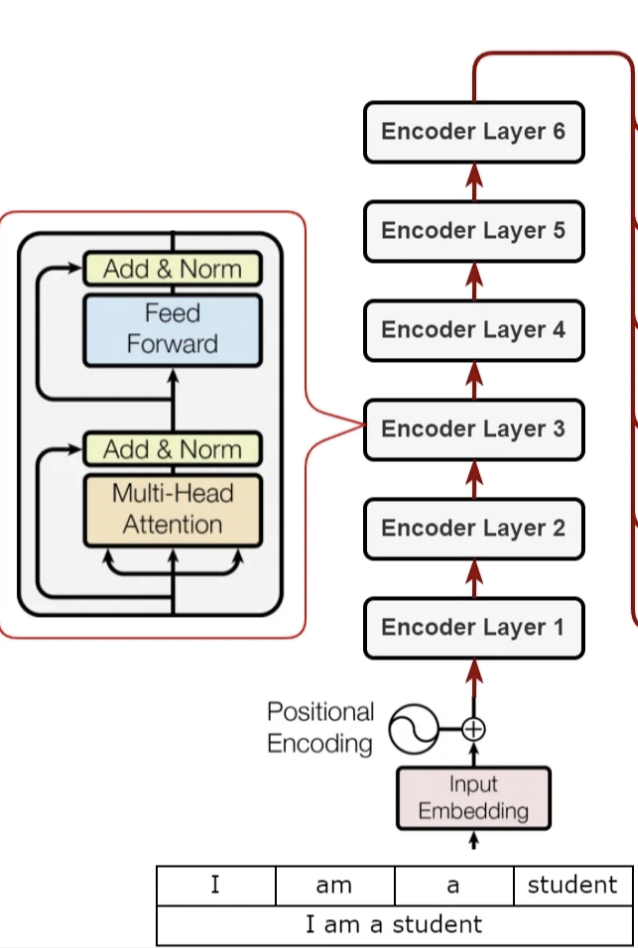

- Encoder층 구성
   - ① Multi-Head Self-Attention: 원문 단어끼리 서로를 보며 문맥 파악
   - ② Feed-Forward Network: 단어 하나하나를 따로 더 깊이 가공
- RNN Encoder와의 차이

| 구분 | RNN / LSTM Encoder | Transformer Encoder |
|---|---|---|
| 읽는 방식 | 단어를 하나씩 순서대로 | 단어를 한꺼번에 |
| 정보 전달 | 이전 시점의 은닉 상태가 다음 시점으로 넘어감 | Self-Attention으로 모든 단어가 서로 직접 연결 |
| 순서 정보 | 읽는 순서 자체에 들어 있음 | Positional Encoding으로 따로 넣어 줌 (순서가 없기 때문) |
| 반복 단위 | RNN / LSTM 셀 | Multi-Head Attention + Feed-Forward 층 |
| 최종 출력 | 마지막 은닉 상태 하나 | 단어별 문맥 벡터 전부 |

- Feed-Forward Network(FFN)

$$
\text{FFN}(x) = \max(0,\ xW_1 + b_1)W_2 + b_2
$$

   - 512차원을 2048차원으로 넓혔다가 다시 512차원으로 좁히는 2층 신경망이고, 사이에 ReLU가 들어감
   - 단어마다 따로, 같은 가중치로 적용되며, 이 단계에서는 단어끼리 정보를 주고받지 않음

- Add & Norm: 모든 부품에 붙음

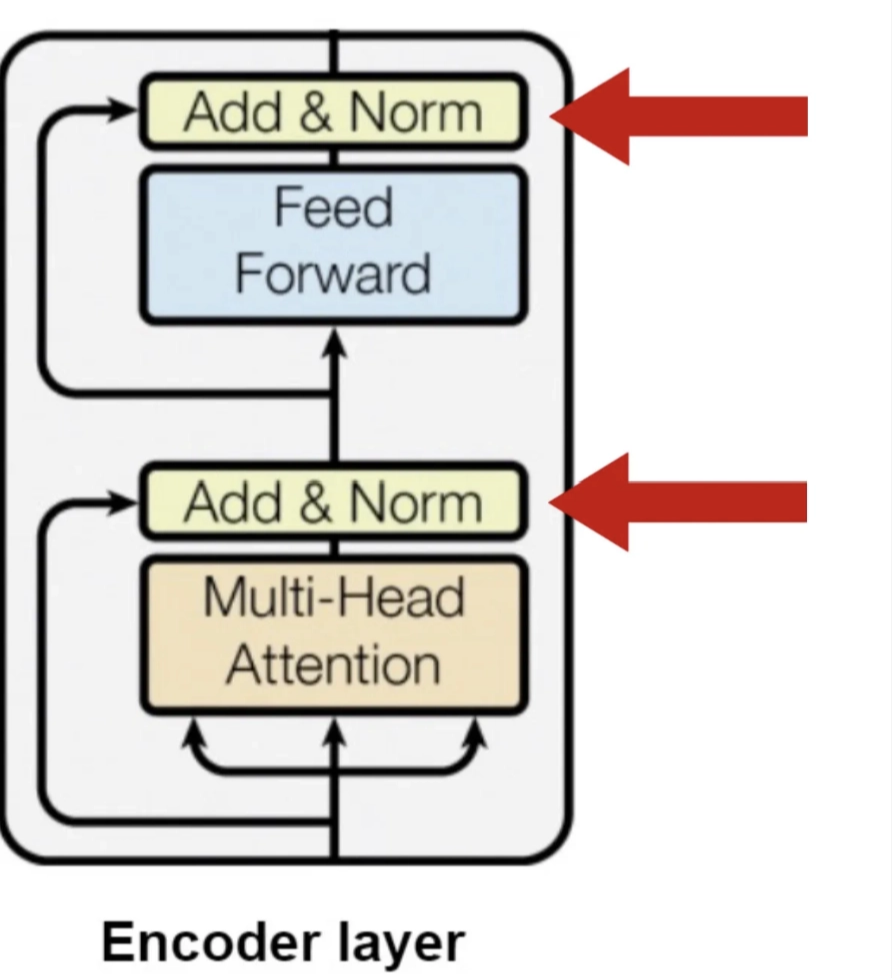

**2) Decoder**

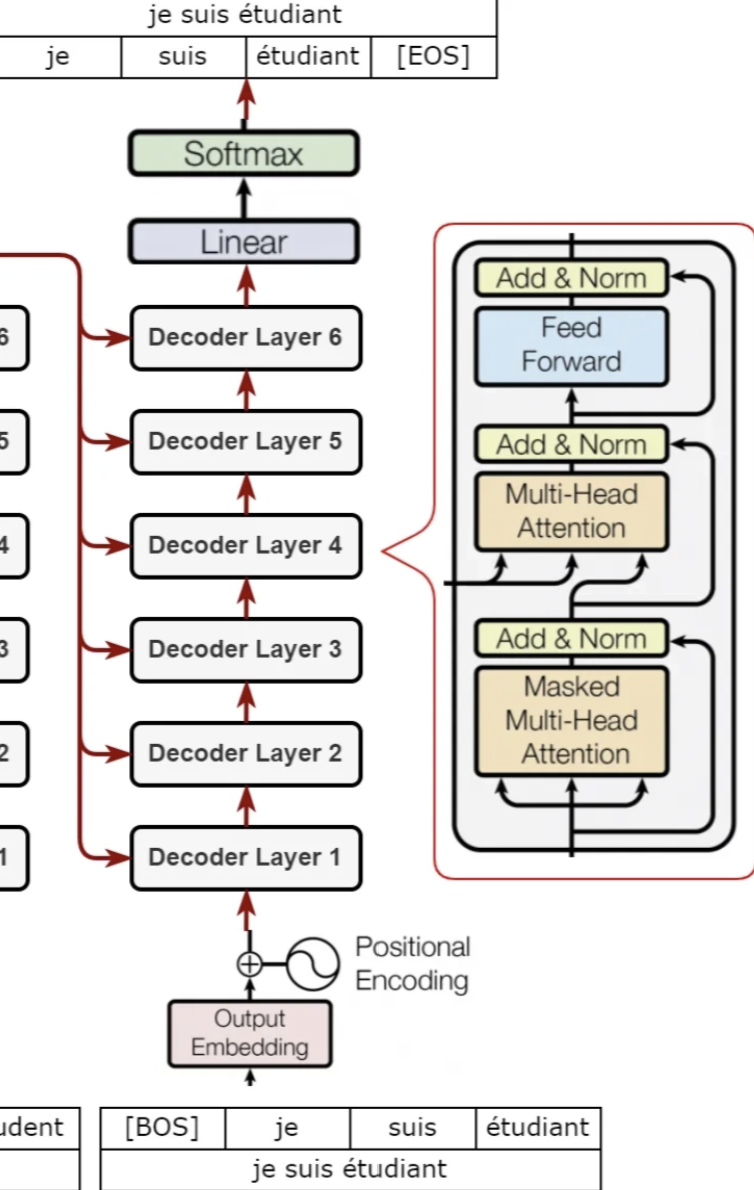

- Decoder 층 구성
   - ① Masked Multi-Head Self-Attention: 지금까지 쓴 번역 단어끼리 관계 파악 (미래 단어는 가림)
   - ② Encoder-Decoder Attention (Cross-Attention): 원문 분석 자료(Encoder 출력)에서 필요한 부분 찾기
   - ③ Feed-Forward Network: Encoder와 동일
- 각각 Add & Norm이 붙으며, 6층을 다 통과하면 Linear + Softmax가 다음 단어의 확률을 계산

- Masked Multi-Head Attention
   - Decoder의 Self-Attention에서 미래 시점의 단어 정보를 가려(Softmax 후 0) 자기보다 앞의 단어만 보게 하는 메커니즘

- Encoder-Decoder Attention (Cross-Attention)

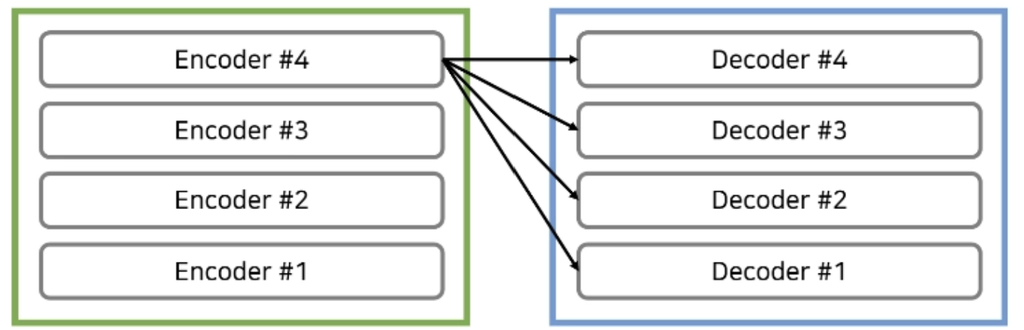

   - 출력 문장(Decoder)과 입력 문장(Encoder)을 연결하는 과정
   - Q·K·V의 출처
      - Q = 직전 Decoder 서브레이어의 출력
      - K·V = Encoder 마지막 층의 출력 (6개 디코더 레이어가 모두 같은 Encoder 출력을 씀)
